<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta6_g%C3%B6rev4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
import torch

print(f"OpenCV Versiyonu: {cv2.__version__}")
print(f"CUDA Kullanılabilir mi (PyTorch/GPU): {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Aktif GPU Modeli: {torch.cuda.get_device_name(0)}")

OpenCV Versiyonu: 4.14.0
CUDA Kullanılabilir mi (PyTorch/GPU): True
Aktif GPU Modeli: Tesla T4


Maksimum oy: 44 | Kullanılan eşik değer: 19
Çizilen çember sayısı: 26


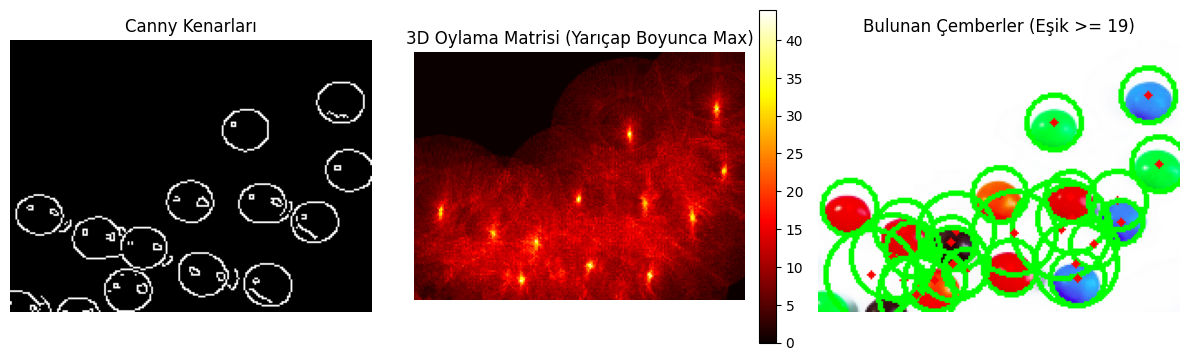

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

url = 'https://raw.githubusercontent.com/opencv/opencv/master/samples/data/smarties.png'
req = urllib.request.urlopen(url)
arr = np.asarray(bytearray(req.read()), dtype=np.uint8)
img = cv2.imdecode(arr, cv2.IMREAD_COLOR)
img = cv2.resize(img, (200, 150))

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
edges = cv2.Canny(gray, 50, 150)

thetas = np.deg2rad(np.arange(0, 360, 5))
cos_vals = np.cos(thetas)
sin_vals = np.sin(thetas)

height, width = edges.shape
radii = np.arange(12, 36, 1)
num_radii = len(radii)

accumulator_3d = np.zeros((height, width, num_radii), dtype=np.int32)

edge_y, edge_x = np.nonzero(edges)

for y, x in zip(edge_y, edge_x):
    for r_idx, r in enumerate(radii):
        for c_val, s_val in zip(cos_vals, sin_vals):
            a = int(round(x - r * c_val))
            b = int(round(y - r * s_val))
            if 0 <= b < height and 0 <= a < width:
                accumulator_3d[b, a, r_idx] += 1

max_votes = accumulator_3d.max()
threshold = int(0.45 * max_votes)
print(f"Maksimum oy: {max_votes} | Kullanılan eşik değer: {threshold}")

b_idxs, a_idxs, r_idxs = np.where(accumulator_3d >= threshold)

img_result = img.copy()
drawn_circles = []

for b, a, r_idx in zip(b_idxs, a_idxs, r_idxs):
    r = int(radii[r_idx])
    if all(np.hypot(a - ea, b - eb) > 12 or abs(r - er) > 6 for ea, eb, er in drawn_circles):
        drawn_circles.append((a, b, r))
        cv2.circle(img_result, (a, b), r, (0, 255, 0), 2)
        cv2.circle(img_result, (a, b), 2, (0, 0, 255), -1)

print(f"Çizilen çember sayısı: {len(drawn_circles)}")

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(edges, cmap='gray')
plt.title('Canny Kenarları')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(accumulator_3d.max(axis=2), cmap='hot')
plt.title('3D Oylama Matrisi (Yarıçap Boyunca Max)')
plt.colorbar(fraction=0.046, pad=0.04)
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(img_result, cv2.COLOR_BGR2RGB))
plt.title(f'Bulunan Çemberler (Eşik >= {threshold})')
plt.axis('off')

plt.tight_layout()
plt.show()